# DineScope — Task 2: Restaurant Recommendation System
## Verification, Evaluation & Demonstration

This notebook verifies the outputs created by the Python implementation in `src/task_2_restaurant_recommendation/`. It does not duplicate data preprocessing, feature engineering or recommendation logic. It loads the saved datasets, recommendation results, evaluation reports, test reports and figures, then checks and presents the outputs.


## 1. Setup and project paths
Run from the project root or the `notebooks/` folder.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Locate the DineScope project root.
def find_project_root() -> Path:
    cwd = Path.cwd()

    for path in [cwd, *cwd.parents]:
        if (path / "src").is_dir() and (path / "data").is_dir():
            return path

    raise FileNotFoundError(
        "Could not locate the DineScope project root. "
        "Open this notebook from inside the DineScope project."
    )


PROJECT_ROOT = find_project_root()

DATA = PROJECT_ROOT / "data" / "processed" / "task_2_restaurant_recommendation"
REPORTS = PROJECT_ROOT / "reports" / "task_2"
FIGURES = PROJECT_ROOT / "outputs" / "figures" / "task_2"

print("=" * 75)
print("DINESCOPE - RESTAURANT INTELLIGENCE & ANALYTICS")
print("TASK 02: RESTAURANT RECOMMENDATION SYSTEM")
print("NOTEBOOK: RECOMMENDATION SYSTEM VERIFICATION")
print("=" * 75)

print("Project root:", PROJECT_ROOT)
print("Processed data:", DATA)
print("Task 2 reports:", REPORTS)
print("Task 2 figures:", FIGURES)

assert DATA.is_dir(), f"Processed data directory not found: {DATA}"
assert REPORTS.is_dir(), f"Task 2 reports directory not found: {REPORTS}"
assert FIGURES.is_dir(), f"Task 2 figures directory not found: {FIGURES}"

print("\nProject directories validated successfully.")

DINESCOPE - RESTAURANT INTELLIGENCE & ANALYTICS
TASK 02: RESTAURANT RECOMMENDATION SYSTEM
NOTEBOOK: RECOMMENDATION SYSTEM VERIFICATION
Project root: c:\Users\kamal\OneDrive\Desktop\DineScope
Processed data: c:\Users\kamal\OneDrive\Desktop\DineScope\data\processed\task_2_restaurant_recommendation
Task 2 reports: c:\Users\kamal\OneDrive\Desktop\DineScope\reports\task_2
Task 2 figures: c:\Users\kamal\OneDrive\Desktop\DineScope\outputs\figures\task_2

Project directories validated successfully.


## 2. Check expected artifacts
Missing files are reported so you can run the corresponding Task 2 script. Some intermediate feature files may have different formats, so this check focuses on the known CSV reports and PNG figures produced by the workflow.


In [2]:
expected_reports = [
    REPORTS / "recommendation_results.csv",
    REPORTS / "recommendation_evaluation_metrics.csv",
    REPORTS / "recommendation_evaluation_results.csv",
    REPORTS / "recommendation_system_test_results.csv",
    REPORTS / "recommendation_system_test_summary.csv",
    REPORTS / "recommendation_performance_summary.csv",
    REPORTS / "recommendation_request_size_analysis.csv",
    REPORTS / "recommendation_scalability_analysis.csv",
    REPORTS / "recommendation_final_summary.csv",
    REPORTS / "recommendation_final_report.txt",
    REPORTS / "interactive_recommendation_history.csv",
]

expected_figures = [
    FIGURES / "01_recommendation_evaluation_metrics.png",
    FIGURES / "02_recommendation_similarity_analysis.png",
    FIGURES / "03_top_recommendations.png",
    FIGURES / "04_cuisine_similarity_vs_rating.png",
    FIGURES / "05_recommendation_evaluation.png",
    FIGURES / "06_component_performance.png",
    FIGURES / "07_request_size_performance.png",
    FIGURES / "08_recommendation_scalability.png",
]

artifact_rows = []

for path in expected_reports + expected_figures:
    artifact_rows.append({
        "Artifact": str(path.relative_to(PROJECT_ROOT)),
        "Type": "Report" if path in expected_reports else "Figure",
        "Status": "Available" if path.exists() else "Missing"
    })

artifact_status = pd.DataFrame(artifact_rows)
display(artifact_status)

missing_artifacts = artifact_status.loc[
    artifact_status["Status"] == "Missing"
]

print("\nAvailable artifacts:", (artifact_status["Status"] == "Available").sum())
print("Missing artifacts:", len(missing_artifacts))

,Artifact,Type,Status
0,reports\task_2\recommendation_results.csv,Report,Available
1,reports\task_2\recommendation_evaluation_metri...,Report,Available
2,reports\task_2\recommendation_evaluation_resul...,Report,Available
3,reports\task_2\recommendation_system_test_resu...,Report,Available
4,reports\task_2\recommendation_system_test_summ...,Report,Available
5,reports\task_2\recommendation_performance_summ...,Report,Available
6,reports\task_2\recommendation_request_size_ana...,Report,Available
7,reports\task_2\recommendation_scalability_anal...,Report,Available
8,reports\task_2\recommendation_final_summary.csv,Report,Available
9,reports\task_2\recommendation_final_report.txt,Report,Available



Available artifacts: 19
Missing artifacts: 0


## 3. Verify the processed recommendation dataset
The recommendation workflow retains the restaurant records, including restaurants without ratings. The preprocessing stage handles missing cuisine information and city-name corrections. This notebook inspects the saved processed dataset; it does not repeat preprocessing.


In [3]:
DATA_FILE = DATA / "recommendation_data.csv"

if not DATA_FILE.exists():
    raise FileNotFoundError(
        f"Processed recommendation dataset not found: {DATA_FILE}. "
        "Run Program 02 first."
    )

recommendation_data = pd.read_csv(DATA_FILE)

print("Dataset shape:", recommendation_data.shape)
print("Total restaurant records:", len(recommendation_data))

print("\nColumns:")
print(recommendation_data.columns.tolist())

print("\nFirst five records:")
display(recommendation_data.head())

print("\nMissing values by column:")
display(
    recommendation_data.isna()
    .sum()
    .sort_values(ascending=False)
    .rename("Missing Values")
    .to_frame()
)

print("\nDataset information:")
recommendation_data.info()

Dataset shape: (9551, 22)
Total restaurant records: 9551

Columns:
['Restaurant ID', 'Restaurant Name', 'Country Code', 'City', 'Address', 'Locality', 'Locality Verbose', 'Longitude', 'Latitude', 'Cuisines', 'Average Cost for two', 'Currency', 'Has Table booking', 'Has Online delivery', 'Is delivering now', 'Switch to order menu', 'Price range', 'Aggregate rating', 'Rating color', 'Rating text', 'Votes', 'Cuisine List']

First five records:


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes,Cuisine List
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"french, japanese, desserts",...,Yes,No,No,No,3,4.8,Dark Green,Excellent,314,['french' 'japanese' 'desserts']
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,japanese,...,Yes,No,No,No,3,4.5,Dark Green,Excellent,591,['japanese']
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"seafood, asian, filipino, indian",...,Yes,No,No,No,4,4.4,Green,Very Good,270,['seafood' 'asian' 'filipino' 'indian']
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"japanese, sushi",...,No,No,No,No,4,4.9,Dark Green,Excellent,365,['japanese' 'sushi']
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"japanese, korean",...,Yes,No,No,No,4,4.8,Dark Green,Excellent,229,['japanese' 'korean']



Missing values by column:


,Missing Values
Aggregate rating,2148
Restaurant ID,0
Country Code,0
City,0
Address,0
Restaurant Name,0
Locality,0
Locality Verbose,0
Latitude,0
Longitude,0



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 9551 entries, 0 to 9550
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Restaurant ID         9551 non-null   int64  
 1   Restaurant Name       9551 non-null   str    
 2   Country Code          9551 non-null   int64  
 3   City                  9551 non-null   str    
 4   Address               9551 non-null   str    
 5   Locality              9551 non-null   str    
 6   Locality Verbose      9551 non-null   str    
 7   Longitude             9551 non-null   float64
 8   Latitude              9551 non-null   float64
 9   Cuisines              9551 non-null   str    
 10  Average Cost for two  9551 non-null   int64  
 11  Currency              9551 non-null   str    
 12  Has Table booking     9551 non-null   str    
 13  Has Online delivery   9551 non-null   str    
 14  Is delivering now     9551 non-null   str    
 15  Switch to 

### 3.1 Inspect key recommendation attributes


In [4]:
key_columns = [
    column for column in [
        "Restaurant ID", "Restaurant Name", "City", "Locality",
        "Cuisines", "Price range", "Aggregate rating", "Votes"
    ]
    if column in recommendation_data.columns
]

display(recommendation_data[key_columns].head(10))

if "Aggregate rating" in recommendation_data.columns:
    print("\nRating availability:")
    display(
        recommendation_data["Aggregate rating"]
        .isna()
        .value_counts()
        .rename(index={False: "Rated", True: "Not rated"})
        .to_frame("Restaurant Count")
    )

if "City" in recommendation_data.columns:
    print("\nTop 10 cities:")
    display(recommendation_data["City"].value_counts().head(10).to_frame("Restaurant Count"))

if "Price range" in recommendation_data.columns:
    print("\nPrice range distribution:")
    display(recommendation_data["Price range"].value_counts().sort_index().to_frame("Restaurant Count"))

,Restaurant ID,Restaurant Name,City,Locality,Cuisines,Price range,Aggregate rating,Votes
0,6317637,Le Petit Souffle,Makati City,"Century City Mall, Poblacion, Makati City","french, japanese, desserts",3,4.8,314
1,6304287,Izakaya Kikufuji,Makati City,"Little Tokyo, Legaspi Village, Makati City",japanese,3,4.5,591
2,6300002,Heat - Edsa Shangri-La,Mandaluyong City,"Edsa Shangri-La, Ortigas, Mandaluyong City","seafood, asian, filipino, indian",4,4.4,270
3,6318506,Ooma,Mandaluyong City,"SM Megamall, Ortigas, Mandaluyong City","japanese, sushi",4,4.9,365
4,6314302,Sambo Kojin,Mandaluyong City,"SM Megamall, Ortigas, Mandaluyong City","japanese, korean",4,4.8,229
5,18189371,Din Tai Fung,Mandaluyong City,"SM Megamall, Ortigas, Mandaluyong City",chinese,3,4.4,336
6,6300781,Buffet 101,Pasay City,"SM by the Bay, Mall of Asia Complex, Pasay City","asian, european",4,4.0,520
7,6301290,Vikings,Pasay City,"SM by the Bay, Mall of Asia Complex, Pasay City","seafood, filipino, asian, european",4,4.2,677
8,6300010,Spiral - Sofitel Philippine Plaza Manila,Pasay City,"Sofitel Philippine Plaza Manila, Pasay City","european, asian, indian",4,4.9,621
9,6314987,Locavore,Pasig City,Kapitolyo,filipino,3,4.8,532



Rating availability:


,Restaurant Count
Aggregate rating,
Rated,7403
Not rated,2148



Top 10 cities:


,Restaurant Count
City,
New Delhi,5473
Gurgaon,1118
Noida,1080
Faridabad,251
Ghaziabad,25
Ahmedabad,21
Amritsar,21
Bhubaneshwar,21
Guwahati,21



Price range distribution:


,Restaurant Count
Price range,
1,4444
2,3113
3,1408
4,586


## 4. Review engineered recommendation features
Program 03 creates the cuisine feature representation and restaurant metadata used by the content-based recommendation workflow. The following cell lists the saved processed artifacts so the feature files can be checked without assuming a particular intermediate file format.


In [5]:
print("Files saved in the processed data directory:")

processed_files = sorted(path for path in DATA.iterdir() if path.is_file())

for path in processed_files:
    print(f"- {path.name} ({path.stat().st_size:,} bytes)")

print("\nThe recommendation feature matrix and metadata are generated by:")
print("src/task_2_restaurant_recommendation/03_recommendation_feature_engineering.py")

Files saved in the processed data directory:
- recommendation_cuisine_features.csv (2,854,283 bytes)
- recommendation_data.csv (2,508,658 bytes)
- recommendation_restaurant_metadata.csv (1,046,146 bytes)

The recommendation feature matrix and metadata are generated by:
src/task_2_restaurant_recommendation/03_recommendation_feature_engineering.py


## 5. Review content-based recommendation results
The recommendation output below is generated by Program 04. It reflects the preference configuration used when that program was last executed.


In [6]:
RESULT_FILE = REPORTS / "recommendation_results.csv"

if not RESULT_FILE.exists():
    raise FileNotFoundError(
        f"Recommendation results not found: {RESULT_FILE}. "
        "Run Program 04 first."
    )

recommendation_results = pd.read_csv(RESULT_FILE)

print("Recommendations generated:", len(recommendation_results))
display(recommendation_results)

required_result_columns = [
    "Restaurant Name",
    "City",
    "Cuisines",
    "Aggregate rating",
    "Cuisine Similarity",
    "Recommendation Score"
]

missing_result_columns = [
    column for column in required_result_columns
    if column not in recommendation_results.columns
]

assert not missing_result_columns, (
    f"Missing recommendation result columns: {missing_result_columns}"
)

assert recommendation_results["Recommendation Score"].notna().all()

Recommendations generated: 10


,Recommendation Rank,Restaurant ID,Restaurant Name,City,Locality,Cuisines,Price range,Aggregate rating,Votes,Cuisine Similarity,Recommendation Score
0,1,18363787,The Culinary Pitaara,New Delhi,Defence Colony,"north indian, chinese",2,4.2,95,1.0,0.976
1,2,18157402,Sid's Kitchen,New Delhi,Kamla Nagar,"north indian, chinese",2,3.8,115,1.0,0.964
2,3,18354639,Panchwati Rasoi,New Delhi,Anand Vihar,"north indian, chinese",1,3.8,62,1.0,0.964
3,4,18246132,Nik's Kitchen,New Delhi,Rohini,"north indian, chinese",2,3.8,56,1.0,0.964
4,5,18454473,Masala Factory,New Delhi,Tagore Garden,"north indian, chinese",2,3.8,18,1.0,0.964
5,6,965,Sethi's Restaurant & Barbeque,New Delhi,Rajouri Garden,"north indian, chinese",2,3.7,422,1.0,0.961
6,7,306,Sagar Ratna,New Delhi,Defence Colony,"north indian, chinese",2,3.7,308,1.0,0.961
7,8,18285729,Farratta,New Delhi,Malviya Nagar,"north indian, chinese",2,3.7,93,1.0,0.961
8,9,6646,Suresh Fast Food,New Delhi,Delhi University-GTB Nagar,"north indian, chinese",1,3.7,91,1.0,0.961
9,10,18322665,Wah Ji Wah,New Delhi,Janakpuri,"north indian, chinese",1,3.7,61,1.0,0.961


### 5.1 Understand the recommendation score
Program 04 and Program 09 use a weighted score that combines cuisine similarity and normalized rating. For restaurants without a rating, the rating component is filled using cuisine similarity.

Recommendation Score = 0.85 X Cuisine Similarity + 0.15 X Rating Score


This is the system's ranking score, not a probability that a restaurant will satisfy a user.


In [7]:
score_columns = [
    column for column in [
        "Restaurant Name", "Cuisine Similarity",
        "Aggregate rating", "Recommendation Score"
    ]
    if column in recommendation_results.columns
]

display(recommendation_results[score_columns].head(10))

print("\nRecommendation score summary:")
display(recommendation_results["Recommendation Score"].describe().to_frame("Recommendation Score"))

,Restaurant Name,Cuisine Similarity,Aggregate rating,Recommendation Score
0,The Culinary Pitaara,1.0,4.2,0.976
1,Sid's Kitchen,1.0,3.8,0.964
2,Panchwati Rasoi,1.0,3.8,0.964
3,Nik's Kitchen,1.0,3.8,0.964
4,Masala Factory,1.0,3.8,0.964
5,Sethi's Restaurant & Barbeque,1.0,3.7,0.961
6,Sagar Ratna,1.0,3.7,0.961
7,Farratta,1.0,3.7,0.961
8,Suresh Fast Food,1.0,3.7,0.961
9,Wah Ji Wah,1.0,3.7,0.961



Recommendation score summary:


,Recommendation Score
count,10.000000
mean,0.963700
std,0.004572
min,0.961000
25%,0.961000
50%,0.962500
75%,0.964000
max,0.976000


## 6. Review recommendation evaluation
Program 05 evaluates the recommendation workflow using five predefined scenarios. The exact cuisine match rate is an internal scenario-level check; it is not a user study or independent ground-truth measure of recommendation relevance.


In [8]:
EVALUATION_FILE = REPORTS / "recommendation_evaluation_metrics.csv"
EVALUATION_RESULTS_FILE = REPORTS / "recommendation_evaluation_results.csv"

if not EVALUATION_FILE.exists() or not EVALUATION_RESULTS_FILE.exists():
    raise FileNotFoundError(
        "Evaluation reports are missing. Run Program 05 first."
    )

evaluation_metrics = pd.read_csv(EVALUATION_FILE)
evaluation_results = pd.read_csv(EVALUATION_RESULTS_FILE)

print("Evaluation metrics:")
display(evaluation_metrics)

print("\nScenario-level recommendation results:")
display(evaluation_results)

print("\nScenario count:", len(evaluation_metrics))

if "Execution Status" in evaluation_metrics.columns:
    display(evaluation_metrics["Execution Status"].value_counts().to_frame("Scenario Count"))

Evaluation metrics:


,Scenario,Description,Cuisine Preferences,City,Price Ranges,Minimum Rating,Eligible Restaurants,Recommendations Generated,Mean Cuisine Similarity,Exact Cuisine Match Rate (%),Zero Similarity Rate (%),Mean Recommended Rating,Rating Coverage (%),Unique Cuisine Combinations,Duplicate Recommendation IDs,Execution Status
0,01_North_Indian,North Indian cuisine preference,north indian,Any,Any,Any,9551,10,1.0,100.0,0.0,4.64,100.0,1,0,PASS
1,02_Multi_Cuisine_New_Delhi,North Indian and Chinese in New Delhi,"north indian, chinese",new delhi,"1, 2",3.5,959,10,1.0,100.0,0.0,3.79,100.0,1,0,PASS
2,03_Italian,Italian cuisine preference,italian,Any,Any,Any,9551,10,1.0,100.0,0.0,4.49,100.0,1,0,PASS
3,04_City_Price_Filter,New Delhi with price ranges 1 and 2,Any,new delhi,"1, 2",Any,4708,10,NaN,NaN,NaN,4.61,100.0,6,0,PASS
4,05_Empty_Result,Nonexistent city to test empty results,Any,__no_matching_city__,Any,Any,0,0,NaN,NaN,NaN,NaN,NaN,0,0,PASS - Empty result handled



Scenario-level recommendation results:


,Scenario,Recommendation Rank,Restaurant ID,Restaurant Name,City,Locality,Cuisines,Price range,Aggregate rating,Votes,City Normalized,Locality Normalized,Is Rated,Cuisine Similarity,Recommendation Score
0,01_North_Indian,1,2100702,Barbeque Nation,Guwahati,Ulubari,north indian,4,4.9,774,guwahati,ulubari,True,1.0,1.00
1,01_North_Indian,2,18416632,The Great Indian Pub,Dehradun,Jakhan,north indian,4,4.9,50,dehradun,jakhan,True,1.0,1.00
2,01_North_Indian,3,18445790,Kopper Kadai,New Delhi,Rajouri Garden,north indian,3,4.8,83,new delhi,rajouri garden,True,1.0,1.00
3,01_North_Indian,4,800089,Barbeque Nation,Lucknow,"Riverside Mall, Gomti Nagar",north indian,4,4.7,1069,lucknow,"riverside mall, gomti nagar",True,1.0,1.00
4,01_North_Indian,5,18357940,Zabardast Indian Kitchen,New Delhi,Connaught Place,north indian,3,4.7,242,new delhi,connaught place,True,1.0,1.00
5,01_North_Indian,6,70393,Bombay Brasserie,Chennai,Nungambakkam,north indian,3,4.6,1753,chennai,nungambakkam,True,1.0,1.00
6,01_North_Indian,7,18420456,Band Baaja Baaraat,New Delhi,Rajouri Garden,north indian,3,4.6,128,new delhi,rajouri garden,True,1.0,1.00
7,01_North_Indian,8,2742,Bukhara - ITC Maurya,New Delhi,"ITC Maurya, Chanakyapuri",north indian,4,4.4,2826,new delhi,"itc maurya, chanakyapuri",True,1.0,1.00
8,01_North_Indian,9,18208924,Rang De Basanti Urban Dhaba,New Delhi,Hauz Khas Village,north indian,3,4.4,541,new delhi,hauz khas village,True,1.0,1.00
9,01_North_Indian,10,18441490,Barbeque Ville,Pune,Wakad,north indian,3,4.4,208,pune,wakad,True,1.0,1.00



Scenario count: 5


,Scenario Count
Execution Status,
PASS,4
PASS - Empty result handled,1


### 6.1 Evaluation interpretation


In [9]:
if "Execution Status" in evaluation_metrics.columns:
    passed_scenarios = evaluation_metrics["Execution Status"].astype(str).str.startswith("PASS").sum()
    total_scenarios = len(evaluation_metrics)

    print(f"Passed scenarios: {passed_scenarios}/{total_scenarios}")
    print(f"Scenario execution pass rate: {passed_scenarios / total_scenarios * 100:.2f}%"
          if total_scenarios else "No evaluation scenarios available.")
else:
    print("Execution Status column is unavailable; inspect the evaluation table above.")

if "Mean Recommended Rating" in evaluation_metrics.columns:
    print("\nMean recommended rating is reported for scenarios with rated recommendations.")
    display(evaluation_metrics[["Scenario", "Mean Recommended Rating"]]
            if "Scenario" in evaluation_metrics.columns
            else evaluation_metrics[["Mean Recommended Rating"]])

Passed scenarios: 5/5
Scenario execution pass rate: 100.00%

Mean recommended rating is reported for scenarios with rated recommendations.


,Scenario,Mean Recommended Rating
0,01_North_Indian,4.64
1,02_Multi_Cuisine_New_Delhi,3.79
2,03_Italian,4.49
3,04_City_Price_Filter,4.61
4,05_Empty_Result,NaN


## 7. Review automated test results
Program 06 tests valid recommendation scenarios, empty-result handling, large recommendation requests and invalid user inputs.


In [10]:
TEST_RESULTS_FILE = REPORTS / "recommendation_system_test_results.csv"
TEST_SUMMARY_FILE = REPORTS / "recommendation_system_test_summary.csv"

if not TEST_RESULTS_FILE.exists() or not TEST_SUMMARY_FILE.exists():
    raise FileNotFoundError(
        "Automated test reports are missing. Run Program 06 first."
    )

test_results = pd.read_csv(TEST_RESULTS_FILE)
test_summary = pd.read_csv(TEST_SUMMARY_FILE)

print("Individual test results:")
display(test_results)

print("\nTest summary:")
display(test_summary)

print("\nNumber of test cases:", len(test_results))
if "Status" in test_results.columns:
    print("\nTest status distribution:")
    display(test_results["Status"].value_counts().to_frame("Test Count"))

Individual test results:


,Test ID,Test Name,Expected Behaviour,Recommendations Generated,Status,Details
0,TC01,Single Cuisine Recommendation,Recommendations should be generated,10,PASS,10 recommendations validated.
1,TC02,Multiple Cuisine Recommendation,Recommendations should match cuisine preferences,10,PASS,10 recommendations validated.
2,TC03,City Filter,All recommendations should belong to New Delhi,10,PASS,10 recommendations validated.
3,TC04,Price Filter,All recommendations should have price range 1 ...,10,PASS,10 recommendations validated.
4,TC05,Minimum Rating Filter,All recommendations should have rating at least 4,10,PASS,10 recommendations validated.
5,TC06,Combined Preference Filter,All selected filters should be satisfied,10,PASS,10 recommendations validated.
6,TC07,No Cuisine Preference,Restaurants should be ranked by rating,10,PASS,10 recommendations validated.
7,TC08,Uncommon Cuisine,Valid uncommon cuisine should be processed,10,PASS,10 recommendations validated.
8,TC09,Empty Result Handling,No recommendations should be returned,0,PASS,Empty result handled correctly.
9,TC10,Large Recommendation Request,Return all available candidates when fewer tha...,9551,PASS,9551 recommendations validated.



Test summary:


,Metric,Value
0,Total Test Cases,14.0
1,Passed Tests,14.0
2,Failed Tests,0.0
3,Execution Errors,0.0
4,Test Pass Rate (%),100.0



Number of test cases: 14

Test status distribution:


,Test Count
Status,
PASS,14


### 7.1 Test validation


In [11]:
assert len(test_results) == 14, (
    f"Expected 14 test cases based on the completed Program 06 run; "
    f"found {len(test_results)}."
)

if "Status" not in test_results.columns:
    raise AssertionError("The test results report does not contain a Status column.")

all_tests_passed = test_results["Status"].eq("PASS").all()

print("All 14 test cases passed:", all_tests_passed)
assert all_tests_passed, "One or more automated test cases did not pass."

All 14 test cases passed: True


## 8. Analyze recommendation system performance
Program 07 measures component execution time, request-size performance and dataset scalability. Timings are environment-specific measurements from this run and should not be interpreted as production service-level guarantees.


In [12]:
PERFORMANCE_FILE = REPORTS / "recommendation_performance_summary.csv"
REQUEST_SIZE_FILE = REPORTS / "recommendation_request_size_analysis.csv"
SCALABILITY_FILE = REPORTS / "recommendation_scalability_analysis.csv"

for path in [PERFORMANCE_FILE, REQUEST_SIZE_FILE, SCALABILITY_FILE]:
    if not path.exists():
        raise FileNotFoundError(
            f"Performance report not found: {path}. Run Program 07."
        )

performance_summary = pd.read_csv(PERFORMANCE_FILE)
request_size_analysis = pd.read_csv(REQUEST_SIZE_FILE)
scalability_analysis = pd.read_csv(SCALABILITY_FILE)

print("Component and complete pipeline performance:")
display(performance_summary)

print("\nRecommendation request-size analysis:")
display(request_size_analysis)

print("\nDataset scalability analysis:")
display(scalability_analysis)

Component and complete pipeline performance:


,Component,Input Restaurants,Output Restaurants,Mean Time (ms),Median Time (ms),Minimum Time (ms),Maximum Time (ms),Peak Python Memory (MB)
0,Cuisine Similarity Computation,9551,9551,5.91738,5.5844,4.7667,8.3209,5.358562
1,Preference Filtering,9551,959,6.00152,5.8195,5.6329,6.6703,0.591256
2,Recommendation Ranking,959,10,4.64000,4.6933,4.1415,5.1250,0.108511
3,Complete Recommendation Pipeline,9551,10,16.60572,16.4798,15.7911,17.2886,5.358562



Recommendation request-size analysis:


,Requested Recommendations,Eligible Restaurants,Recommendations Generated,Mean Time (ms),Median Time (ms),Minimum Time (ms),Maximum Time (ms),Peak Python Memory (MB)
0,5,959,5,18.18538,18.5226,16.6831,19.3584,5.358562
1,10,959,10,17.29612,17.3147,16.3759,17.9360,5.358459
2,25,959,25,16.82298,16.8565,16.3786,17.0800,5.358511
3,50,959,50,18.13488,17.9718,17.0293,19.6165,5.358562



Dataset scalability analysis:


,Dataset Percentage,Restaurants Processed,Eligible Restaurants,Recommendations Generated,Mean Time (ms),Median Time (ms),Minimum Time (ms),Maximum Time (ms),Peak Python Memory (MB)
0,25,2387,247,10,12.54658,12.3967,11.7871,13.4870,1.364197
1,50,4775,472,10,14.25476,14.2917,13.1367,15.0975,2.694132
2,75,7163,736,10,15.88708,15.6717,14.9512,16.8775,4.024118
3,100,9551,959,10,16.63252,16.9738,15.8521,17.2596,5.358562


### 8.1 Performance interpretation


In [13]:
time_column = "Median Time (ms)"

if time_column in performance_summary.columns:
    display(
        performance_summary[
            [column for column in ["Component", "Input Restaurants",
                                   "Output Restaurants", time_column,
                                   "Peak Python Memory (MB)"]
             if column in performance_summary.columns]
        ]
    )
else:
    print("Median Time (ms) column not found; inspect the performance report above.")

print("\nNote: tracemalloc reports Python-tracked allocations and does not represent total process or native-library memory.")

,Component,Input Restaurants,Output Restaurants,Median Time (ms),Peak Python Memory (MB)
0,Cuisine Similarity Computation,9551,9551,5.5844,5.358562
1,Preference Filtering,9551,959,5.8195,0.591256
2,Recommendation Ranking,959,10,4.6933,0.108511
3,Complete Recommendation Pipeline,9551,10,16.4798,5.358562



Note: tracemalloc reports Python-tracked allocations and does not represent total process or native-library memory.


## 9. Display generated evaluation and analysis figures
The figures below are generated by Programs 05 and 08. Missing images are reported without stopping the notebook.



01_recommendation_evaluation_metrics.png


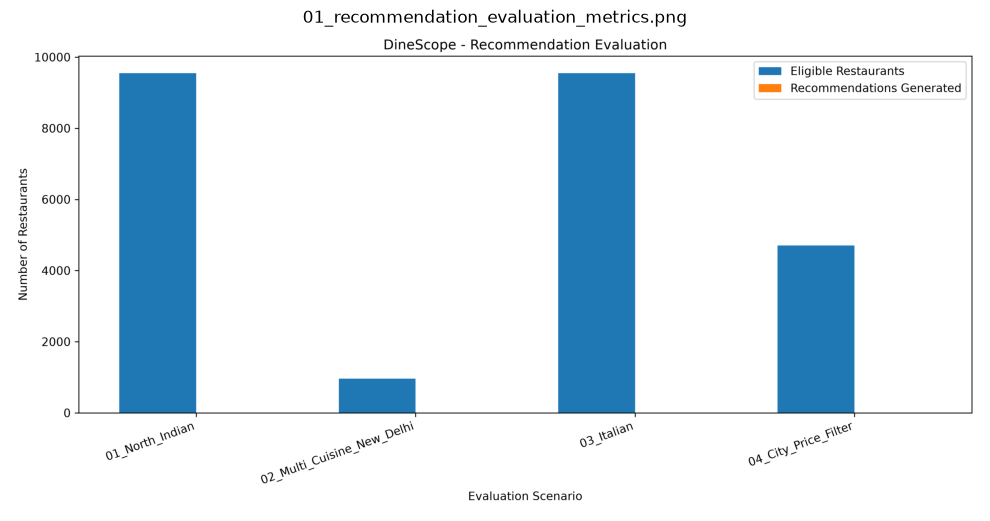


02_recommendation_similarity_analysis.png


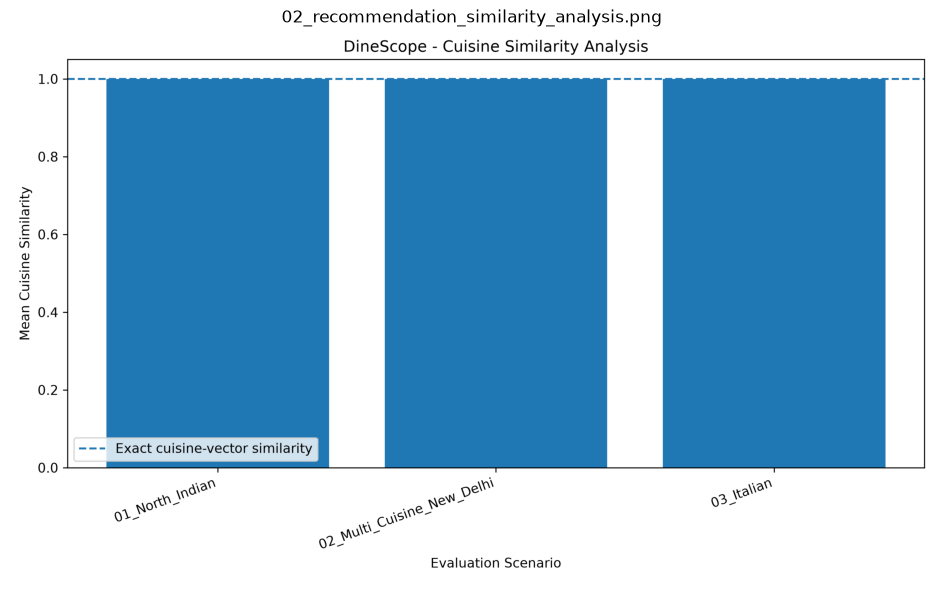


03_top_recommendations.png


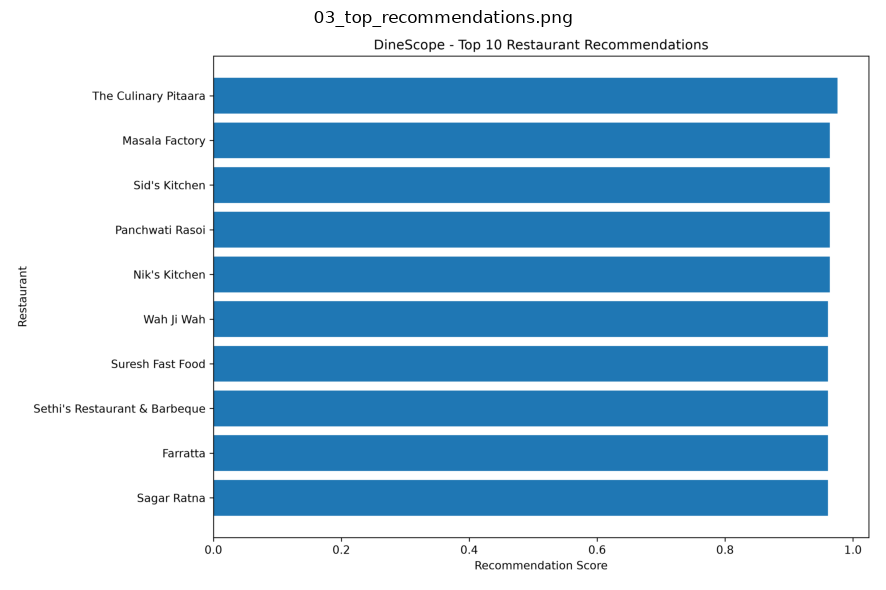


04_cuisine_similarity_vs_rating.png


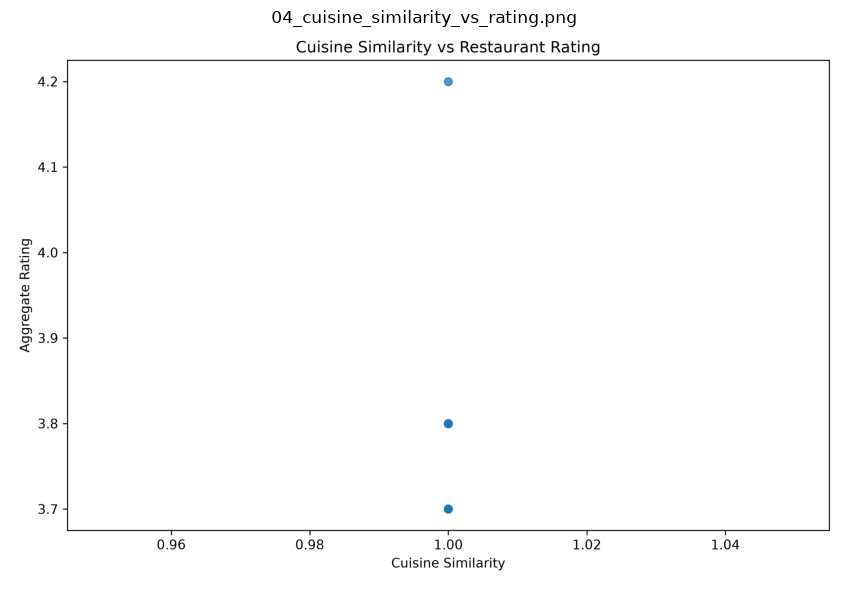


05_recommendation_evaluation.png


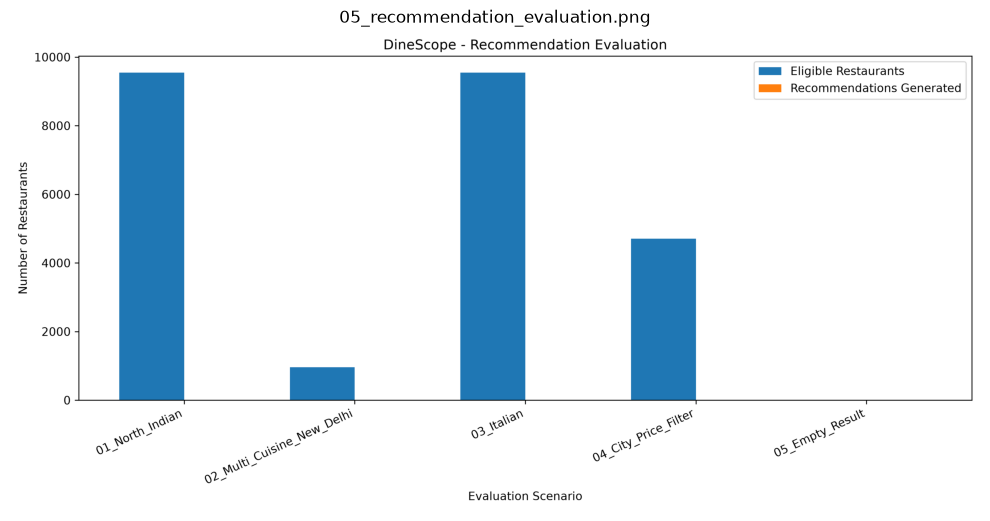


06_component_performance.png


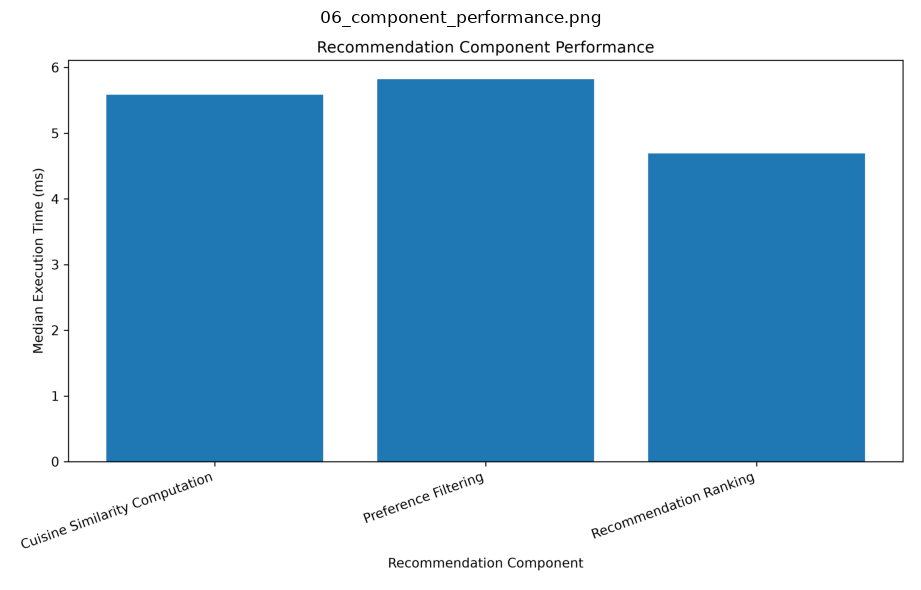


07_request_size_performance.png


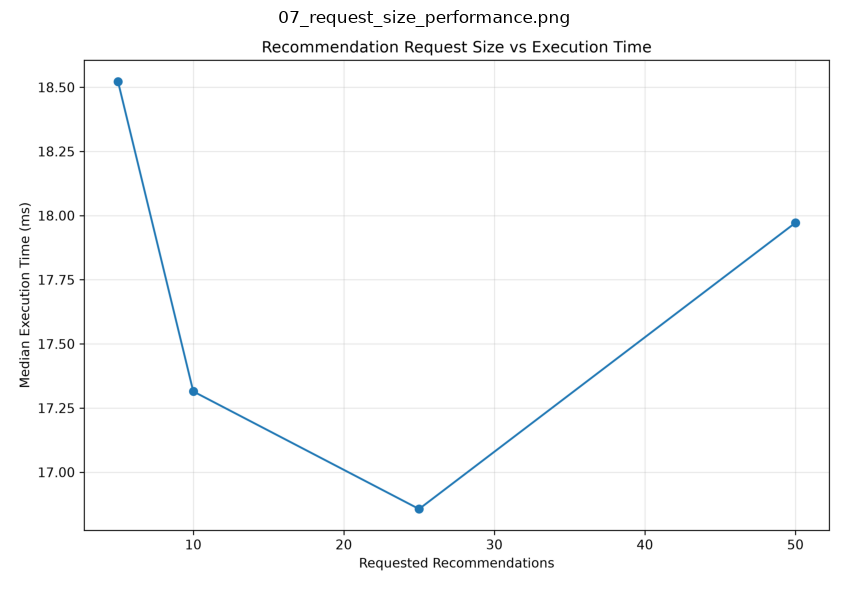


08_recommendation_scalability.png


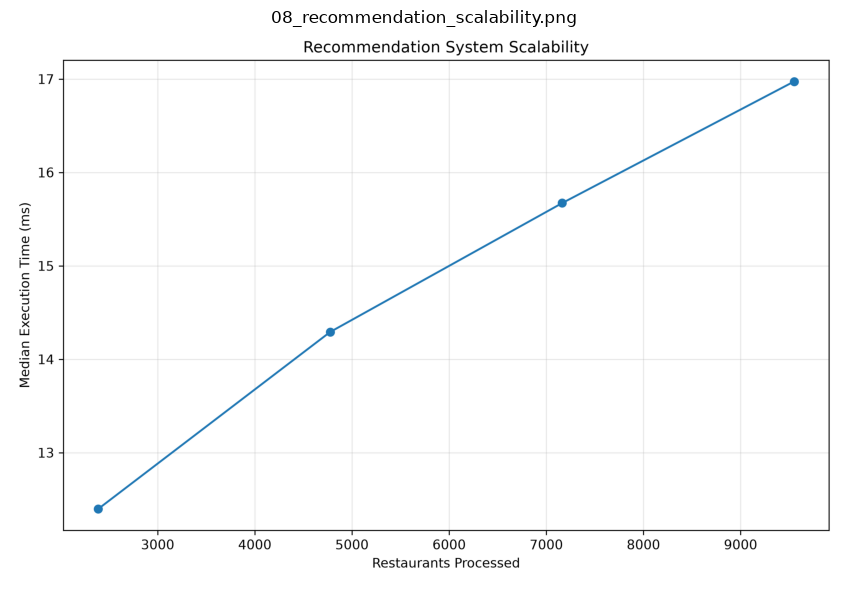

Generated figures: 8 / 8


In [14]:
figure_files = [
    "01_recommendation_evaluation_metrics.png",
    "02_recommendation_similarity_analysis.png",
    "03_top_recommendations.png",
    "04_cuisine_similarity_vs_rating.png",
    "05_recommendation_evaluation.png",
    "06_component_performance.png",
    "07_request_size_performance.png",
    "08_recommendation_scalability.png"
]

for filename in figure_files:
    figure_path = FIGURES / filename

    if figure_path.exists():
        print("\n" + filename)
        image = plt.imread(figure_path)
        plt.figure(figsize=(10, 6))
        plt.imshow(image)
        plt.axis("off")
        plt.title(filename)
        plt.tight_layout()
        plt.show()
    else:
        print("Figure not found:", filename)

available_figures = [
    FIGURES / name
    for name in figure_files
    if (FIGURES / name).exists()
]

print("Generated figures:", len(available_figures), "/", len(figure_files))

assert len(available_figures) == 8, (
    "Expected all 8 recommendation visualizations."
)

## 10. Review the consolidated final report
Program 08 combines recommendation, evaluation, testing and performance results into a summary CSV and text report.


In [15]:
SUMMARY_FILE = REPORTS / "recommendation_final_summary.csv"
FINAL_REPORT_FILE = REPORTS / "recommendation_final_report.txt"

if SUMMARY_FILE.exists():
    final_summary = pd.read_csv(SUMMARY_FILE)
    display(final_summary)
else:
    print("Final summary CSV not found.")

if FINAL_REPORT_FILE.exists():
    print("\nFinal text report:\n")
    print(FINAL_REPORT_FILE.read_text(encoding="utf-8"))
else:
    print("Final text report not found.")

,Metric,Value
0,Total Restaurants in Dataset,9551.0000
1,Recommendations Generated,10.0000
2,Evaluation Scenarios,5.0000
3,Evaluation Scenarios Passed,5.0000
4,Total Test Cases,14.0000
5,Passed Tests,14.0000
6,Failed Tests,0.0000
7,Test Pass Rate (%),100.0000
8,Complete Pipeline Median Time (ms),16.4798



Final text report:

DINESCOPE - RESTAURANT INTELLIGENCE & ANALYTICS
TASK 02: RESTAURANT RECOMMENDATION SYSTEM
PROGRAM 08: FINAL VISUALIZATION AND REPORTING

1. RECOMMENDATION OVERVIEW
Recommendations in latest result file: 10

2. EVALUATION OVERVIEW
Total evaluation scenarios: 5
Passed evaluation scenarios: 5
Failed evaluation scenarios: 0

3. AUTOMATED TESTING
Total test cases: 14.0
Passed tests: 14.0
Failed tests: 0.0
Test pass rate (%): 100.0

4. PERFORMANCE OVERVIEW
Complete pipeline median time (ms): 16.479800000524847

5. GENERATED VISUALIZATIONS
03_top_recommendations.png
04_cuisine_similarity_vs_rating.png
05_recommendation_evaluation.png
06_component_performance.png
07_request_size_performance.png
08_recommendation_scalability.png

6. INTERPRETATION AND LIMITATIONS
This report consolidates outputs from the recommendation
engine, evaluation, automated testing and performance analysis.

The evaluation scenarios and automated tests validate
implemented behavior against predefine

## 11. Review interactive recommendation history
This reads the history created by `src/task_2_restaurant_recommendation/09_interactive_recommendation_system.py`; it does not launch the terminal application.


In [16]:
HISTORY_FILE = REPORTS / "interactive_recommendation_history.csv"

if HISTORY_FILE.exists():
    recommendation_history = pd.read_csv(HISTORY_FILE)

    print("Interactive recommendation history loaded.")
    print("History shape:", recommendation_history.shape)
    display(recommendation_history.head(10))
else:
    print("No interactive recommendation history file found yet.")
    print("Run Program 09 to generate this file.")

Interactive recommendation history loaded.
History shape: (40, 19)


,Selected Cuisines,Selected City,Selected Locality,Selected Price Ranges,Minimum Rating,Requested Recommendations,Eligible Restaurants,Session Timestamp,Recommendation Rank,Restaurant ID,Restaurant Name,City,Locality,Cuisines,Price range,Aggregate rating,Votes,Cuisine Similarity,Recommendation Score
0,"north indian, chinese",new delhi,Any,"1, 2",3.5,10,959,2026-11-23T14:10:20,1,18363787,The Culinary Pitaara,New Delhi,Defence Colony,"north indian, chinese",2,4.2,95,1.0,0.976
1,"north indian, chinese",new delhi,Any,"1, 2",3.5,10,959,2026-11-23T14:10:20,2,18157402,Sid's Kitchen,New Delhi,Kamla Nagar,"north indian, chinese",2,3.8,115,1.0,0.964
2,"north indian, chinese",new delhi,Any,"1, 2",3.5,10,959,2026-11-23T14:10:20,3,18354639,Panchwati Rasoi,New Delhi,Anand Vihar,"north indian, chinese",1,3.8,62,1.0,0.964
3,"north indian, chinese",new delhi,Any,"1, 2",3.5,10,959,2026-11-23T14:10:20,4,18246132,Nik's Kitchen,New Delhi,Rohini,"north indian, chinese",2,3.8,56,1.0,0.964
4,"north indian, chinese",new delhi,Any,"1, 2",3.5,10,959,2026-11-23T14:10:20,5,18454473,Masala Factory,New Delhi,Tagore Garden,"north indian, chinese",2,3.8,18,1.0,0.964
5,"north indian, chinese",new delhi,Any,"1, 2",3.5,10,959,2026-11-23T14:10:20,6,965,Sethi's Restaurant & Barbeque,New Delhi,Rajouri Garden,"north indian, chinese",2,3.7,422,1.0,0.961
6,"north indian, chinese",new delhi,Any,"1, 2",3.5,10,959,2026-11-23T14:10:20,7,306,Sagar Ratna,New Delhi,Defence Colony,"north indian, chinese",2,3.7,308,1.0,0.961
7,"north indian, chinese",new delhi,Any,"1, 2",3.5,10,959,2026-11-23T14:10:20,8,18285729,Farratta,New Delhi,Malviya Nagar,"north indian, chinese",2,3.7,93,1.0,0.961
8,"north indian, chinese",new delhi,Any,"1, 2",3.5,10,959,2026-11-23T14:10:20,9,6646,Suresh Fast Food,New Delhi,Delhi University-GTB Nagar,"north indian, chinese",1,3.7,91,1.0,0.961
9,"north indian, chinese",new delhi,Any,"1, 2",3.5,10,959,2026-11-23T14:10:20,10,18322665,Wah Ji Wah,New Delhi,Janakpuri,"north indian, chinese",1,3.7,61,1.0,0.961


## 12. Verify Program 04 and Program 09 output consistency
Programs 04 and 09 are intended to use the same recommendation score calculation. This section compares their saved top-result tables only if both outputs are available in the expected reports. The interactive history file may contain a different schema, so the comparison is performed only when the required fields exist.


In [17]:
comparison_columns = [
    "Restaurant Name", "Cuisine Similarity", "Recommendation Score"
]

if (
    HISTORY_FILE.exists()
    and all(column in recommendation_results.columns for column in comparison_columns)
):
    history_columns_available = all(
        column in recommendation_history.columns
        for column in comparison_columns
    )

    if history_columns_available:
        program04_top = recommendation_results[comparison_columns].head(10).reset_index(drop=True)
        latest_timestamp = recommendation_history["Session Timestamp"].max()

        latest_session = recommendation_history[
            recommendation_history["Session Timestamp"] == latest_timestamp
        ].copy()

        if "Recommendation Rank" in latest_session.columns:
            latest_session = latest_session.sort_values("Recommendation Rank")

        program09_top = (
            latest_session[comparison_columns]
            .head(10)
            .reset_index(drop=True)
        )

        print("Program 04 top results:")
        display(program04_top)

        print("Program 09 saved history:")
        display(program09_top)

        print(
            "Exact table equality:",
            program04_top.equals(program09_top)
        )
    else:
        print(
            "The interactive history schema does not contain the same result columns. "
            "The terminal output can be compared manually with Program 04."
        )
else:
    print("Program 04/09 comparison skipped because the required result fields are unavailable.")

Program 04 top results:


,Restaurant Name,Cuisine Similarity,Recommendation Score
0,The Culinary Pitaara,1.0,0.976
1,Sid's Kitchen,1.0,0.964
2,Panchwati Rasoi,1.0,0.964
3,Nik's Kitchen,1.0,0.964
4,Masala Factory,1.0,0.964
5,Sethi's Restaurant & Barbeque,1.0,0.961
6,Sagar Ratna,1.0,0.961
7,Farratta,1.0,0.961
8,Suresh Fast Food,1.0,0.961
9,Wah Ji Wah,1.0,0.961


Program 09 saved history:


,Restaurant Name,Cuisine Similarity,Recommendation Score
0,The Culinary Pitaara,1.0,0.976
1,Sid's Kitchen,1.0,0.964
2,Panchwati Rasoi,1.0,0.964
3,Nik's Kitchen,1.0,0.964
4,Masala Factory,1.0,0.964
5,Sethi's Restaurant & Barbeque,1.0,0.961
6,Sagar Ratna,1.0,0.961
7,Farratta,1.0,0.961
8,Suresh Fast Food,1.0,0.961
9,Wah Ji Wah,1.0,0.961


Exact table equality: False


## 13. Final Task 2 verification
This final section checks the key generated artifacts and the completed evaluation/test reports. It does not rerun the recommendation algorithm.


In [18]:
final_checks = {
    "Processed recommendation dataset exists": DATA_FILE.exists(),
    "Recommendation results exist": RESULT_FILE.exists(),
    "Evaluation metrics report exists": EVALUATION_FILE.exists(),
    "Evaluation scenario results exist": EVALUATION_RESULTS_FILE.exists(),
    "Automated test results exist": TEST_RESULTS_FILE.exists(),
    "Automated test summary exists": TEST_SUMMARY_FILE.exists(),
    "Performance summary exists": PERFORMANCE_FILE.exists(),
    "Request-size report exists": REQUEST_SIZE_FILE.exists(),
    "Scalability report exists": SCALABILITY_FILE.exists(),
    "Final summary exists": SUMMARY_FILE.exists(),
    "Final text report exists": FINAL_REPORT_FILE.exists(),
    "Recommendation cuisine features exist": (DATA / "recommendation_cuisine_features.csv").exists(),
    "Recommendation restaurant metadata exists": (DATA / "recommendation_restaurant_metadata.csv").exists(),
}

for name, status in final_checks.items():
    print(f"{name}: {'PASS' if status else 'FAIL'}")

print("\nEvaluation scenarios:", len(evaluation_metrics))
print("Automated test cases:", len(test_results))

if "Status" in test_results.columns:
    print("Automated tests passed:", int(test_results["Status"].eq("PASS").sum()))
    print("Automated tests failed:", int((test_results["Status"] != "PASS").sum()))

assert all(final_checks.values()), "One or more required Task 2 artifacts are missing."
assert len(evaluation_metrics) == 5, "Expected five evaluation scenarios."
assert len(test_results) == 14, "Expected fourteen automated test cases."
assert test_results["Status"].eq("PASS").all(), "At least one automated test failed."

print("\nTASK 02 VERIFICATION CHECKS COMPLETED.")

Processed recommendation dataset exists: PASS
Recommendation results exist: PASS
Evaluation metrics report exists: PASS
Evaluation scenario results exist: PASS
Automated test results exist: PASS
Automated test summary exists: PASS
Performance summary exists: PASS
Request-size report exists: PASS
Scalability report exists: PASS
Final summary exists: PASS
Final text report exists: PASS
Recommendation cuisine features exist: PASS
Recommendation restaurant metadata exists: PASS

Evaluation scenarios: 5
Automated test cases: 14
Automated tests passed: 14
Automated tests failed: 0

TASK 02 VERIFICATION CHECKS COMPLETED.


## 14. Conclusion

Task 2 implements a content-based restaurant recommendation workflow using cuisine features, restaurant metadata and user preference filters.

### Workflow covered
- Recommendation data auditing and preprocessing.
- Cuisine feature engineering.
- Content-based similarity and recommendation ranking.
- Scenario-based recommendation evaluation.
- Automated valid-input and invalid-input testing.
- Component, request-size and dataset-scalability performance analysis.
- Visualization and consolidated reporting.
- Interactive terminal-based recommendation.

### Reported results from the completed execution
- **9,551** restaurant records in the recommendation dataset.
- **145** cuisine features.
- **5/5** evaluation scenarios passed.
- **14/14** automated test cases passed.
- **16.6606 ms** median complete-pipeline execution time in the recorded benchmark.

### Limitations
1. The evaluation scenarios are predefined and do not constitute a user study.
2. Exact cuisine matching is an internal evaluation proxy, not independent relevance ground truth.
3. Performance measurements are specific to the local environment and dataset size.
4. The recommendation system is content-based; it does not establish personalized user preferences from historical interaction data.
5. The interactive application is terminal-based, not a deployed web application.
6. Dataset provenance and redistribution permissions should be confirmed before publishing the dataset or derived artifacts.

**Core implementation:** `src/task_2_restaurant_recommendation/`  
**Primary recommendation output:** `reports/task_2/recommendation_results.csv`  
**Interactive application:** `src/task_2_restaurant_recommendation/09_interactive_recommendation_system.py`

**Task 2 status:** Core implementation, evaluation, testing, performance analysis and local output verification completed.


## 15. Interactive Restaurant Recommendation — Custom Preference Testing

### Objective
Test the interactive restaurant recommendation application using custom preferences entered by the user.

### Instructions
1. Open the VS Code integrated terminal.
2. Ensure the DineScope virtual environment is activated.
3. Execute the interactive recommendation application.
4. Enter preferred cuisines, city, locality, price range, minimum rating and recommendation count.
5. Review the recommended restaurants and their recommendation scores.
6. Verify that the interactive session history is saved.

### Execute the application

Run the following command from the DineScope project root:

```powershell
python src/task_2_restaurant_recommendation/09_interactive_recommendation_system.py
```

### Expected outcome
- Display the available cuisine labels.
- Accept user preference inputs.
- Apply cuisine, city, locality, price and rating filters.
- Rank eligible restaurants using the recommendation score.
- Display the requested number of recommendations.
- Save the interactive recommendation session history.

**Note:** This application uses the engineered features created by Program 03. It does not retrain a machine-learning model.
